# Breast Cancer Wisconsin - Diagnostic
### Context

Clinical imaging dataset describing breast masses using quantitative characteristics extracted from digitised images of fine needle aspirates. The variables describe different morphological properties of cell nuclei.

### Dimensionality and Structure

The dataset contains 569 samples described by 30 continuous variables. Each sample is associated with a binary diagnosis: benign or malignant.

### Possible Questions

Supervised learning: Predict whether a breast mass is benign or malignant.
Unsupervised learning: Determine whether samples naturally separate into groups corresponding to benign and malignant diagnoses.
Additional analysis: Identify the morphological variables that are the most discriminative.


# Unsupervised learning

### Summary 
##### 1. Library
##### 2. Data
##### 3. Preprocessing
##### 4. Principal component analysis (PCA)
##### 5. K-means Clustering
##### 6. Agglomerative Clustering
##### 7. Spectral Clustering
##### 8. Comparison with the True Diagnosis
##### 9. Silhouette Score
##### 10. Conclusion

### 1. Library

In [60]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, roc_curve, roc_auc_score)
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import SpectralClustering
import seaborn as sns
from sklearn.model_selection import train_test_split

In [61]:
COLORS = {
    "blue": "#AFCBE8",
    "orange": "#F2C6A5",
    "green": "#B8D8C0",
    "pink": "#E6B8B8",
    "purple": "#C8B6D8",
    "grey": "#D9D9D9"
}

### 2.Data 
The Breast Cancer Wisconsin Diagnostic dataset contains 569 observations
described by 30 continuous morphological features.
These features quantify different characteristics of cell nuclei, such as
radius, texture, perimeter, area, smoothness, compactness, concavity and
concave points.
Each observation is associated with a diagnosis indicating whether the tumour
is malignant (M) or benign (B).
The diagnosis will not be used to construct the clusters. It will only be
used later to evaluate how well the unsupervised methods recover the known
clinical categories.

In [62]:
breast_data = pd.read_csv('/Users/apple/Desktop/Project UE1_AIDA/10_Breast_Cancer_Wisconsin_Diagnostic.csv')

# Display the first 10 observations as a formatted table
display(breast_data.head(10).style.set_caption("Breast Cancer Wisconsin — Diagnostic Dataset").set_table_styles([
    {"selector": "caption","props": [("font-size", "16px"),("font-weight", "bold"),("text-align", "left")]},
        {"selector": "th","props": [("font-weight", "bold"),("text-align", "center")]},
        {"selector": "td","props": [("text-align", "center")]}]).format(precision=2))

print(f"Number of observations: {breast_data.shape[0]}")
print(f"Number of variables: {breast_data.shape[1]}")

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.00,0.12,0.28,0.30,0.15,0.24,0.08,1.09,0.91,8.59,153.40,0.01,0.05,0.05,0.02,0.03,0.01,25.38,17.33,184.60,2019.00,0.16,0.67,0.71,0.27,0.46,0.12
1,842517,M,20.57,17.77,132.90,1326.00,0.08,0.08,0.09,0.07,0.18,0.06,0.54,0.73,3.40,74.08,0.01,0.01,0.02,0.01,0.01,0.00,24.99,23.41,158.80,1956.00,0.12,0.19,0.24,0.19,0.28,0.09
2,84300903,M,19.69,21.25,130.00,1203.00,0.11,0.16,0.20,0.13,0.21,0.06,0.75,0.79,4.58,94.03,0.01,0.04,0.04,0.02,0.02,0.00,23.57,25.53,152.50,1709.00,0.14,0.42,0.45,0.24,0.36,0.09
3,84348301,M,11.42,20.38,77.58,386.10,0.14,0.28,0.24,0.11,0.26,0.10,0.50,1.16,3.44,27.23,0.01,0.07,0.06,0.02,0.06,0.01,14.91,26.50,98.87,567.70,0.21,0.87,0.69,0.26,0.66,0.17
4,84358402,M,20.29,14.34,135.10,1297.00,0.10,0.13,0.20,0.10,0.18,0.06,0.76,0.78,5.44,94.44,0.01,0.02,0.06,0.02,0.02,0.01,22.54,16.67,152.20,1575.00,0.14,0.20,0.40,0.16,0.24,0.08
5,843786,M,12.45,15.70,82.57,477.10,0.13,0.17,0.16,0.08,0.21,0.08,0.33,0.89,2.22,27.19,0.01,0.03,0.04,0.01,0.02,0.01,15.47,23.75,103.40,741.60,0.18,0.52,0.54,0.17,0.40,0.12
6,844359,M,18.25,19.98,119.60,1040.00,0.09,0.11,0.11,0.07,0.18,0.06,0.45,0.77,3.18,53.91,0.00,0.01,0.02,0.01,0.01,0.00,22.88,27.66,153.20,1606.00,0.14,0.26,0.38,0.19,0.31,0.08
7,84458202,M,13.71,20.83,90.20,577.90,0.12,0.16,0.09,0.06,0.22,0.07,0.58,1.38,3.86,50.96,0.01,0.03,0.02,0.01,0.01,0.01,17.06,28.14,110.60,897.00,0.17,0.37,0.27,0.16,0.32,0.12
8,844981,M,13.00,21.82,87.50,519.80,0.13,0.19,0.19,0.09,0.23,0.07,0.31,1.00,2.41,24.32,0.01,0.04,0.04,0.01,0.02,0.00,15.49,30.73,106.20,739.30,0.17,0.54,0.54,0.21,0.44,0.11
9,84501001,M,12.46,24.04,83.97,475.90,0.12,0.24,0.23,0.09,0.20,0.08,0.30,1.60,2.04,23.94,0.01,0.07,0.08,0.01,0.02,0.01,15.09,40.68,97.65,711.40,0.19,1.06,1.10,0.22,0.44,0.21


Number of observations: 569
Number of variables: 32


### 3. Preprocessing

Before applying clustering algorithms, the dataset is checked for potential
data quality issues and prepared for analysis.
First, the patient identifier (`id`) is removed because it does not contain
biological information. The diagnosis is also excluded from the clustering
features because it represents the target variable and would introduce
supervised information into the analysis.
The remaining 30 morphological variables are then standardized using
StandardScaler. This is necessary because the variables have very different
scales and ranges.
Finally, missing values, duplicate observations and duplicated identifiers
are checked before proceeding with the analysis.

In [72]:
#Remove "id" and "diagnosis"
data_features = breast_data.drop(["id", "diagnosis"], axis=1)

#change "B" to 1 and "M" to 0
breast_data["diagnosis"] = breast_data["diagnosis"].map({"M": 0, "B": 1})

Because several morphological measurements describe related characteristics,
some features may be strongly correlated. A correlation matrix is therefore
used to identify potential redundancy between variables.

Number of missing values:
Series([], dtype: int64)

✓ No missing values detected in the dataset.
Number of duplicate rows: 0

✓ No duplicate observations detected.
Number of duplicated IDs: 0

✓ No duplicated IDs detected.


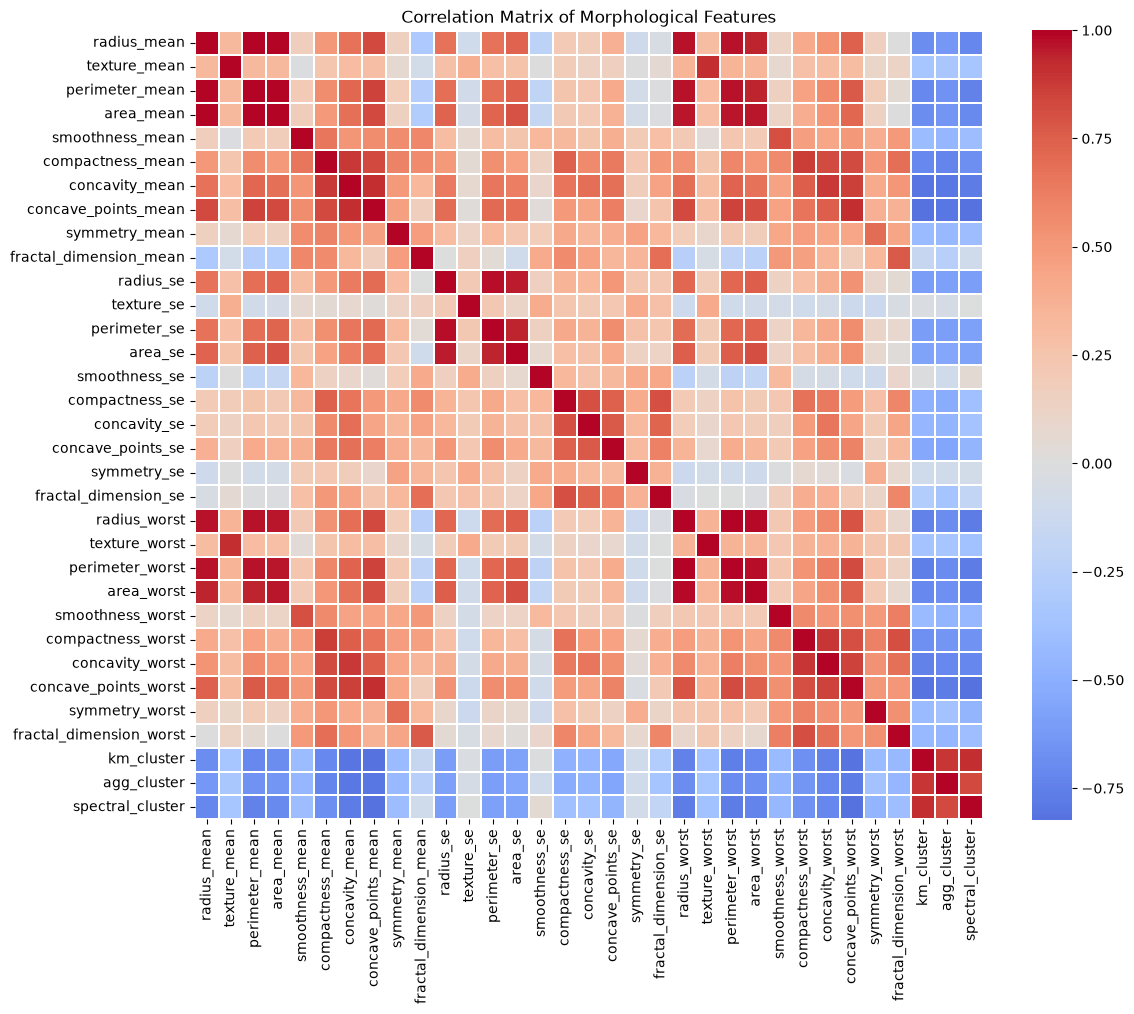

In [73]:
#Standardization
scaler = StandardScaler()
features_scaled = scaler.fit_transform(data_features)

#Missing values
missing_values = breast_data.isnull().sum()

print("Number of missing values:")
print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("\n✓ No missing values detected in the dataset.")

# Check for duplicate observations
duplicate_rows = breast_data.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")
if duplicate_rows == 0:
    print("\n✓ No duplicate observations detected.")

# Check for duplicate IDs
duplicate_ids = breast_data["id"].duplicated().sum()
print(f"Number of duplicated IDs: {duplicate_ids}")
if duplicate_ids == 0:
    print("\n✓ No duplicated IDs detected.")

#Correlation between features
plt.figure(figsize=(12, 10))
correlation_matrix = data_features.corr()
sns.heatmap(correlation_matrix,cmap="coolwarm",center=0,square=True,linewidths=0.2)

plt.title("Correlation Matrix of Morphological Features")
plt.tight_layout()
plt.show()

### 4. Principal Component Analysis

Principal Component Analysis (PCA) is used to explore the structure of the dataset and reduce its dimensionality for visualization.
PCA transforms the original 30 standardized morphological variables into a new set of uncorrelated variables called principal components.
The first principal component (PC1) explains the largest possible proportion of the variance, while PC2 explains the largest proportion of the remaining variance.

The PCA is performed without using the diagnosis. The diagnosis is only used afterwards to colour the observations in the PCA plot, allowing us to visually assess whether benign and malignant samples show a natural separation.

PC1 explains 46.92% of the variance
PC2 explains 17.28% of the variance
Total explained variance: 64.20%



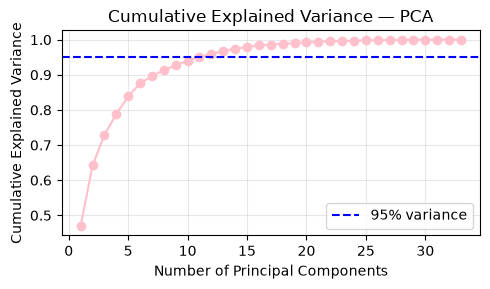

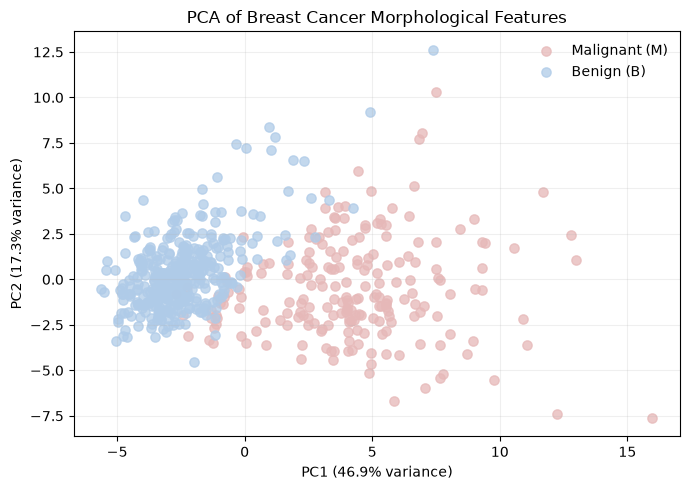

In [77]:
# PCA to assess dimensionality
pca = PCA()
pca.fit(features_scaled)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

# Apply PCA on the standardized morphological features
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_scaled)

# Explained variance
print(f"PC1 explains {pca.explained_variance_ratio_[0]*100:.2f}% of the variance")
print(f"PC2 explains {pca.explained_variance_ratio_[1]*100:.2f}% of the variance")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum()*100:.2f}%\n")

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(cumulative_variance) + 1),cumulative_variance,marker="o", color="pink")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance — PCA")
plt.axhline(y=0.95,linestyle="--",label="95% variance", color="blue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#Malign and Begnin Clusters
plt.figure(figsize=(7, 5))
plt.scatter(features_pca[breast_data["diagnosis"] == 0, 0],features_pca[breast_data["diagnosis"] == 0, 1],label="Malignant (M)",
            color=COLORS["pink"],alpha=0.75,s=45)

plt.scatter(features_pca[breast_data["diagnosis"] == 1, 0],features_pca[breast_data["diagnosis"] == 1, 1],label="Benign (B)",
    color=COLORS["blue"],alpha=0.75,s=45)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA of Breast Cancer Morphological Features")
plt.legend(frameon=False)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

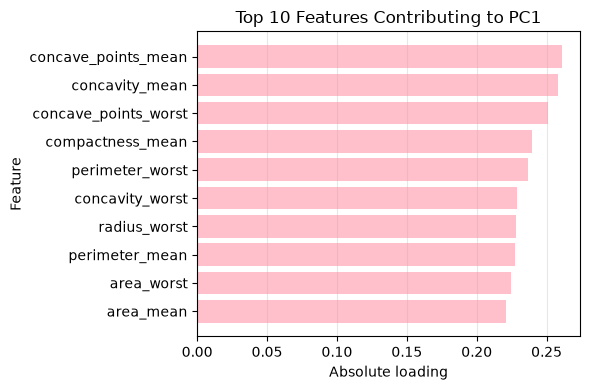

In [66]:
pca_components = pd.DataFrame(pca.components_,columns=data_features.columns,index=["PC1", "PC2"])
pc1_importance = (pca_components.loc["PC1"].abs().sort_values(ascending=True).tail(10))


plt.figure(figsize=(6, 4))
plt.barh(pc1_importance.index,pc1_importance.values, color="pink")
plt.xlabel("Absolute loading")
plt.ylabel("Feature")
plt.title("Top 10 Features Contributing to PC1")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 5. K-means Clustering

K-means is an unsupervised clustering algorithm that partitions observations into a predefined number of clusters.
The algorithm assigns each observation to the nearest centroid and iteratively updates the centroid positions until the assignments stabilize.
Two clusters are initially considered in order to investigate whether the dataset naturally separates into two groups.
The diagnosis is not used during model fitting. Only the 30 standardized morphological features are used.

In [79]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_clusters = kmeans.fit_predict(features_scaled)
breast_data["km_cluster"] = kmeans_clusters

### 6. Agglomerative Clustering

Agglomerative Clustering is a hierarchical clustering method.
Unlike K-means, which starts by defining a fixed number of clusters, the agglomerative approach initially considers each observation as an individual cluster. The closest clusters are then progressively merged until all observations belong to a single cluster.
The resulting hierarchical structure can be represented using a dendrogram.
In this analysis, Ward's linkage method is used. This method selects the merge that results in the smallest increase in within cluster variance.
As with K-means, the clustering algorithm is applied exclusively to the 30 standardized morphological features and does not use the diagnosis.

In [78]:
#Agglomerative clustering
agg = AgglomerativeClustering(n_clusters=2)
agg_clusters = agg.fit_predict(features_scaled)

breast_data["agg_cluster"] = agg_clusters

### 7. Spectral Clustering

Spectral Clustering is a graph-based clustering method.
Unlike K-means, which directly assigns observations according to their distance from cluster centroids, Spectral Clustering first constructs a similarity graph between observations. The algorithm then uses the eigenvectors of the graph Laplacian to obtain a lower-dimensional representation of the data, on which clustering is performed.
In this analysis, two clusters are considered in order to compare the results with the two known clinical categories. The diagnosis is not used during model fitting.

In [80]:
spectral = SpectralClustering(n_clusters=2,affinity='nearest_neighbors',n_neighbors=10,random_state=42)
spectral_clusters = spectral.fit_predict(features_scaled)
breast_data["spectral_cluster"] = spectral_clusters

### 8. Comparison of the methods

Although the diagnosis was not used to construct the clusters, it can be used retrospectively to evaluate whether the identified groups correspond to the known clinical categories.
Contingency tables are used to compare the cluster assignments with the true diagnosis.
Because cluster labels are arbitrary, cluster 0 does not inherently represent malignant tumours and cluster 1 does not inherently represent benign tumours. The accuracy is therefore calculated independently of the assignment of cluster labels.
A higher accuracy indicates a stronger correspondence between the unsupervised clusters and the known diagnosis.

In [81]:
from sklearn.metrics import accuracy_score

# Function to calculate accuracy while accounting for arbitrary cluster labels
def cluster_accuracy(y_true, clusters):
    acc_1 = accuracy_score(y_true, clusters)
    acc_2 = accuracy_score(y_true, 1 - clusters)
    return max(acc_1, acc_2)


# Calculate accuracies
accuracy_km = cluster_accuracy(breast_data["diagnosis"],breast_data["km_cluster"])
accuracy_agg = cluster_accuracy(breast_data["diagnosis"],breast_data["agg_cluster"])
accuracy_spectral = cluster_accuracy(breast_data["diagnosis"],breast_data["spectral_cluster"])


# Create contingency tables
table_km = pd.crosstab(breast_data["diagnosis"],breast_data["km_cluster"])

table_agg = pd.crosstab(breast_data["diagnosis"],breast_data["agg_cluster"])

table_spectral = pd.crosstab(breast_data["diagnosis"],breast_data["spectral_cluster"])


# Rename diagnosis labels
for table in [table_km, table_agg, table_spectral]:
    table.index = ["Malignant (M)", "Benign (B)"]
    table.index.name = "True diagnosis"
    table.columns.name = "Cluster"


# Display tables
from IPython.display import display, HTML

# Convert tables to HTML
html_km = (table_km.style.set_caption(f"K-means — Accuracy: {accuracy_km:.2%}").set_table_styles([
        {"selector": "caption","props": [("font-size", "14px"),("font-weight", "bold"),("text-align", "center")]},
        {"selector": "th","props": [("text-align", "center")]},{"selector": "td","props": [("text-align", "center")]}]).to_html())

html_agg = (table_agg.style.set_caption(f"Agglomerative — Accuracy: {accuracy_agg:.2%}").set_table_styles([
        {"selector": "caption","props": [("font-size", "14px"),("font-weight", "bold"),("text-align", "center")]},
        {"selector": "th","props": [("text-align", "center")]},{"selector": "td","props": [("text-align", "center")]}]).to_html())

html_spectral = (table_spectral.style.set_caption(f"Spectral — Accuracy: {accuracy_spectral:.2%}").set_table_styles([
    {"selector": "caption","props": [("font-size", "14px"),("font-weight", "bold"),("text-align", "center")]},{"selector": "th",
         "props": [("text-align", "center")]},{"selector": "td","props": [("text-align", "center")]}]).to_html())

# Display side by side
display(HTML(f"""<div style="display: flex;justify-content: space-between;gap: 25px;width: 100%;"><div style="flex: 1;">{html_km}</div>
<div style="flex: 1;">{html_agg}</div><div style="flex: 1;">{html_spectral}</div></div>"""))

Cluster,0,1
True diagnosis,,
Malignant (M),176,36
Benign (B),12,345
Cluster,0,1
True diagnosis,,
Malignant (M),49,163
Benign (B),354,3
Cluster,0,1
True diagnosis,,
Malignant (M),178,34


### 9. Silhouette score

The Silhouette Score is used to evaluate the intrinsic quality of the clusters, without using the known diagnosis.
For each observation, the Silhouette Score considers both its similarity to observations within its own cluster and its separation from observations in the other cluster.
The score ranges from -1 to 1. Higher values indicate better-defined clusters, with observations that are more similar within their own cluster and more separated from the other cluster.
The Silhouette Score is therefore complementary to the comparison with the true diagnosis: it evaluates the structure of the clusters independently of the clinical labels.

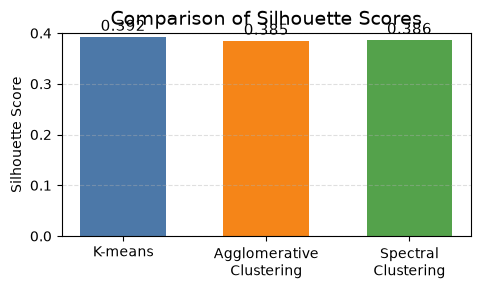

In [82]:
silhouette_kmeans = []
silhouette_agg = []
silhouette_spectral = []

silhouette_km = silhouette_score(features_scaled,kmeans_clusters)
silhouette_agg = silhouette_score(features_scaled,agg_clusters)
silhouette_spectral = silhouette_score(features_scaled,spectral_clusters)


methods = ["K-means","Agglomerative\nClustering","Spectral\nClustering"]
scores = [silhouette_km,silhouette_agg,silhouette_spectral]
plt.figure(figsize=(5, 3))
color = ["#4C78A8", "#F58518", "#54A24B"]
bars = plt.bar(methods, scores, width=0.6, color=color)

# Add values above each bar
for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width() / 2,score + 0.005,f"{score:.3f}",ha="center",va="bottom",fontsize=11)
plt.ylabel("Silhouette Score")
plt.title("Comparison of Silhouette Scores", fontsize=14)

# Adapt the y-axis to the observed values
plt.ylim(0, 0.4)

# Light horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 10. Conclusion

This project investigated whether unsupervised learning methods could identify natural groupings in the Breast Cancer Wisconsin Diagnostic dataset using only morphological features. After data quality checks, the dataset was preprocessed by removing the patient identifier and the diagnosis from the clustering features, followed by standardization of the 30 morphological variables. PCA was also used to explore
the structure of the dataset and to visualize the observations in a reduced dimensional space.

Three unsupervised clustering methods were compared: K-means, Agglomerative Clustering and Spectral Clustering. The results show that all three methods were able to identify clusters that correspond relatively well to the known benign and malignant diagnoses.
Spectral Clustering achieved the highest agreement with the true diagnosis, with an accuracy of 93.67%, followed by K-means with 91.21% and Agglomerative Clustering with 88.05%. This suggests that the graph-based approach was the most effective at recovering the clinical separation present in the dataset.

However, the Silhouette Scores were very similar across the three methods: 0.345 for K-means, 0.339 for Agglomerative Clustering and 0.337 for Spectral Clustering. K-means therefore produced the best-defined clusters according to the intrinsic clustering criterion, although the difference between the methods was small.
Overall, these results show that the morphological features contain strong information related to the distinction between benign and malignant tumours, even when the diagnosis is not provided to the clustering algorithms. However, the clustering results should not be interpreted as a clinical diagnostic model. The diagnosis was used only retrospectively for evaluation, and further analysis would be required to assess the robustness and clinical relevance of these findings.

# Supervised Learning

##### 1. Processing of the data
##### 2. Logistic Regression
##### 3. Support Vector Machine (SVM)
##### 4. Random Forest
##### 5.Comparison of the model
##### 6. Confusion matices
##### 7. ROC curves and AUC
##### 8. Features importance
##### 9. Conclusion

### 1. Processing of the data 

##### Definition of X and y

The morphological variables are used as predictors, while the diagnosis is used as the target variable.
The patient ID is excluded because it does not contain relevant biological information.

In [97]:
breast_data2 = pd.read_csv('/Users/apple/Desktop/Project UE1_AIDA/10_Breast_Cancer_Wisconsin_Diagnostic2.csv')

features = ["radius_mean","texture_mean","perimeter_mean","area_mean","smoothness_mean",
            "compactness_mean","concavity_mean","concave_points_mean","symmetry_mean",
            "fractal_dimension_mean","radius_se","texture_se","perimeter_se",
            "area_se","smoothness_se","compactness_se","concavity_se","concave_points_se",
            "symmetry_se","fractal_dimension_se","radius_worst","texture_worst","perimeter_worst",
            "area_worst","smoothness_worst","compactness_worst","concavity_worst",
            "concave_points_worst","symmetry_worst","fractal_dimension_worst"]

#change "B" to 1 and "M" to 0
breast_data2["diagnosis"] = breast_data2["diagnosis"].map({"M": 0, "B": 1})

#Defined X and y
X = breast_data2[features]
y = breast_data2["diagnosis"]

##### Train-test split

The dataset is divided into a training set and a test set.
The training set is used to fit the models, while the test set is kept independent and is used to evaluate their performance on unseen data.

In [99]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,
                                                    random_state=42,stratify=y)

In [100]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining diagnosis:")
print(y_train.value_counts())

print("\nTest diagnosis:")
print(y_test.value_counts())

Training set: (455, 30)
Test set: (114, 30)

Training diagnosis:
diagnosis
1    285
0    170
Name: count, dtype: int64

Test diagnosis:
diagnosis
1    72
0    42
Name: count, dtype: int64


##### Standardization

The morphological variables have different scales. Standardization is therefore performed before classification.
The scaler is fitted only on the training data and then applied to both the training and test sets in order to avoid data leakage.

In [101]:
scaler_supervised = StandardScaler()
X_train_scaled = scaler_supervised.fit_transform(X_train)
X_test_scaled = scaler_supervised.transform(X_test)

### 2. Logistic Regression

Logistic regression is used as a baseline classification model for predicting whether a tumour is benign or malignant.
The model estimates the probability that an observation belongs to one of the two diagnostic classes.

In [102]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression accuracy:", accuracy_logistic)

Logistic Regression accuracy: 0.9824561403508771


### 3. Support Vector Machine 

A Support Vector Machine (SVM) is used to find a decision boundary separating benign and malignant observations.
Because the dataset contains several correlated morphological variables, SVM can be useful for identifying a boundary between the two diagnostic classes.

In [104]:
from sklearn.svm import SVC
svm_model = SVC(kernel="rbf",probability=True,random_state=42)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

print("SVM")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))

SVM
Accuracy: 0.9824561403508771


/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### 4. Random Forest 

Random Forest is an ensemble classification method based on multiple decision trees.
It is used both to evaluate predictive performance and to identify the morphological features that contribute most to the classification.

In [105]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("the Accuracy for the Random Forest model is :", accuracy_score(y_test, y_pred_rf))

the Accuracy for the Random Forest model is : 0.956140350877193


### 5. Comparison of performances

In [107]:
def evaluate_model(y_true, y_pred, y_prob, model_name):
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    
    return {"Model": model_name,"Accuracy": accuracy,"Precision": precision,
        "Recall": recall,"F1-score": f1,"AUC": auc}

In [108]:
results = []

results.append(evaluate_model(y_test,y_pred_logistic,y_prob_logistic,"Logistic Regression"))

results.append(evaluate_model(y_test,y_pred_svm,y_prob_svm,"SVM"))

results.append(evaluate_model(y_test,y_pred_rf,y_prob_rf,"Random Forest"))

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-score,AUC
0,Logistic Regression,0.982456,0.986111,0.986111,0.986111,0.995370
1,SVM,0.982456,0.986111,0.986111,0.986111,0.995040
2,Random Forest,0.956140,0.958904,0.972222,0.965517,0.993056


In [109]:
def calculate_specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp)
    return specificity

specificity_logistic = calculate_specificity(y_test, y_pred_logistic)
specificity_svm = calculate_specificity(y_test, y_pred_svm)
specificity_rf = calculate_specificity(y_test, y_pred_rf)

print("Logistic Regression specificity:", specificity_logistic)
print("SVM specificity:", specificity_svm)
print("Random Forest specificity:", specificity_rf)

Logistic Regression specificity: 0.9761904761904762
SVM specificity: 0.9761904761904762
Random Forest specificity: 0.9285714285714286


### 6. Confusion Matrix

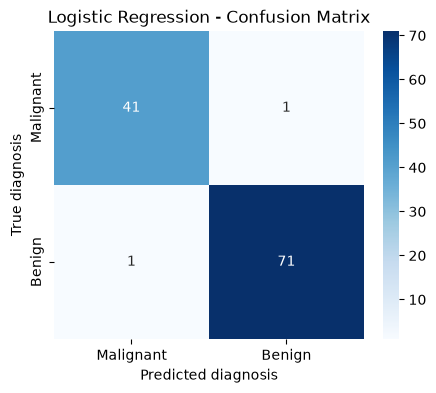

In [110]:
#Logistic Regression Confusion Matrix

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_logistic, annot=True,fmt="d",cmap="Blues",xticklabels=["Malignant", "Benign"],
            yticklabels=["Malignant", "Benign"])
plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

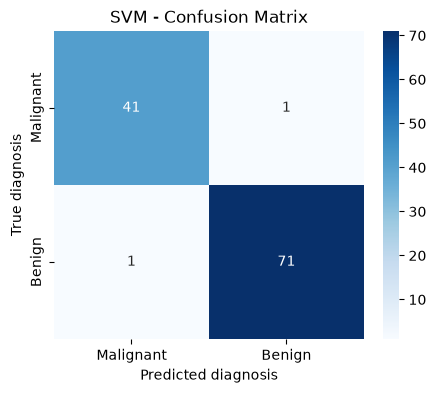

In [111]:
# Support Vector Machine (SVM) Confusion Matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_svm,annot=True,fmt="d",cmap="Blues",
    xticklabels=["Malignant", "Benign"],yticklabels=["Malignant", "Benign"])

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")
plt.title("SVM - Confusion Matrix")
plt.show()

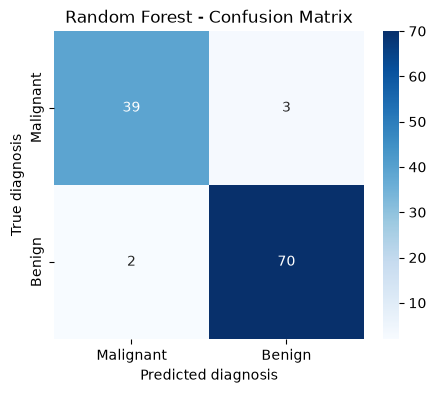

In [112]:
# Random Forest Confusion Matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_rf,annot=True,fmt="d",cmap="Blues",
    xticklabels=["Malignant", "Benign"],yticklabels=["Malignant", "Benign"])

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")
plt.title("Random Forest - Confusion Matrix")
plt.show()

### 7. ROC curves

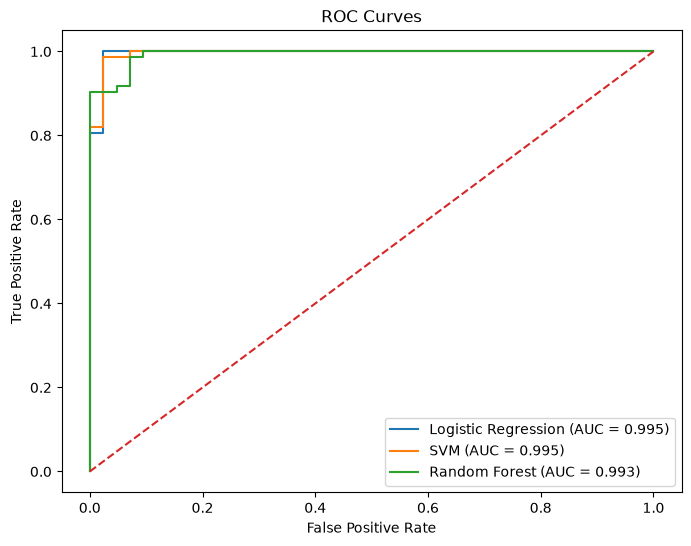

In [113]:
fpr_logistic, tpr_logistic, _ = roc_curve(y_test,y_prob_logistic,
    pos_label=1)
fpr_svm, tpr_svm, _ = roc_curve(y_test,y_prob_svm,pos_label=1)
fpr_rf, tpr_rf, _ = roc_curve(y_test,y_prob_rf,pos_label=1)

auc_logistic = roc_auc_score(y_test, y_prob_logistic)
auc_svm = roc_auc_score(y_test, y_prob_svm)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_logistic,tpr_logistic,label=f"Logistic Regression (AUC = {auc_logistic:.3f})")
plt.plot(fpr_svm,tpr_svm,label=f"SVM (AUC = {auc_svm:.3f})")
plt.plot(fpr_rf,tpr_rf,label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

### 8. Features importance

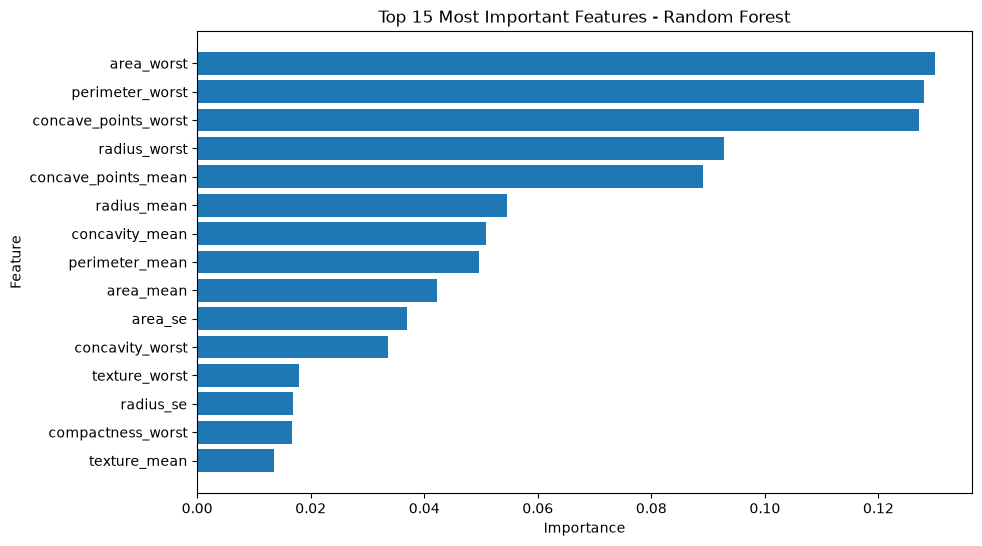

In [114]:
# Random Forest feature importance

feature_importance = pd.DataFrame({"Feature": X.columns,
                                   "Importance": rf_model.feature_importances_})

feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
feature_importance.head(15)

plt.figure(figsize=(10, 6))
top_features = feature_importance.head(15)

plt.barh(top_features["Feature"][::-1],top_features["Importance"][::-1])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Most Important Features - Random Forest")

plt.show()

In [115]:
# Logistic Regression coefficients

logistic_coefficients = pd.DataFrame({"Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]})

logistic_coefficients["Absolute_Coefficient"] = (logistic_coefficients["Coefficient"].abs())

logistic_coefficients = logistic_coefficients.sort_values(by="Absolute_Coefficient",
    ascending=False)

logistic_coefficients.head(15)

,Feature,Coefficient,Absolute_Coefficient
21,texture_worst,-1.255088,1.255088
10,radius_se,-1.082965,1.082965
27,concave_points_worst,-0.953686,0.953686
23,area_worst,-0.947756,0.947756
20,radius_worst,-0.947616,0.947616
28,symmetry_worst,-0.939181,0.939181
13,area_se,-0.929104,0.929104
26,concavity_worst,-0.823151,0.823151
22,perimeter_worst,-0.763220,0.763220
24,smoothness_worst,-0.746625,0.746625


In [116]:
feature_comparison = feature_importance.merge(logistic_coefficients, on="Feature")

feature_comparison.sort_values(by="Importance",ascending=False).head(15)

,Feature,Importance,Coefficient,Absolute_Coefficient
0,area_worst,0.130008,-0.947756,0.947756
1,perimeter_worst,0.127948,-0.763220,0.763220
2,concave_points_worst,0.127183,-0.953686,0.953686
3,radius_worst,0.092807,-0.947616,0.947616
4,concave_points_mean,0.089029,-0.704156,0.704156
5,radius_mean,0.054538,-0.511479,0.511479
6,concavity_mean,0.050924,-0.602103,0.602103
7,perimeter_mean,0.049703,-0.476298,0.476298
8,area_mean,0.042165,-0.541059,0.541059
9,area_se,0.037021,-0.929104,0.929104
